# Exercise 6..: training a Field-of-Experts regularizer
In this exercise we will train two simple reconstruction networks for

- an image denoising problem and
- an image inpainting inverse problem

Follow these steps for each inverse problem:

1. Get a dataset of images. You can use the CBSD68 dataset for training and the set3c dataset for testing. Resize images to 128x128 pixels (larger images take longer to train, and for this exercise, we can work with smaller images). Split the training set into 60 training and 8 validation images.
2. Define the forward operator (identity plus noise for denoising problem or masking operator for inpainting problem).
3. Define the reconstruction architecture. Use a [U-Net](https://arxiv.org/pdf/1505.04597) (a common neural network architecture for imaging problems) $R_\theta$ with trainable parameters $\theta$. The reconstruction of a corrupted image $y$ is $\hat{x} = R_\theta(y)$. After training the network by optimizing its parameters $\theta$ we expect $\hat x \approx y$.
4. Train the reconstruction network on the training data. At each training epoch plot the PSNR of reconstructions and example images of source, measurements, and reconstruction.
5. Test the trained network on your testset and compare the PSNR before and after training on the testset.
6. Plot examples of reconstructed test images.



## Change runtime type and install DeepInverse package
First, we install the deepinverse library. Remeber to change the runtime of this notebook select ``Runtime`` -> ``Change runtime type`` and pick an available hardware accelerator.

In [ ]:
!pip install git+https://github.com/deepinv/deepinv.git#egg=deepinv

  Cloning https://github.com/deepinv/deepinv.git to /tmp/pip-install-e1lcznm5/deepinv_1bad9b5c52884c469583ec31b815fd6e
  Running command git clone --filter=blob:none --quiet https://github.com/deepinv/deepinv.git /tmp/pip-install-e1lcznm5/deepinv_1bad9b5c52884c469583ec31b815fd6e
  Resolved https://github.com/deepinv/deepinv.git to commit f304b6adc964e0054fd182d1044c7af11d2d116a
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 77.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 64.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━

In [1]:
import deepinv as dinv
from torch.utils.data import DataLoader
import torch
from pathlib import Path
from torchvision import transforms
from deepinv.utils.demo import load_dataset

import matplotlib.pyplot as plt

# Setup paths for data loading and checkpoints

In [2]:
BASE_DIR = Path(".")
DATA_DIR = BASE_DIR / "measurements"
CKPT_DIR = BASE_DIR / "ckpts"

# Set the global random seed from pytorch to ensure reproducibility of the example.
torch.manual_seed(0)

device = dinv.utils.get_freer_gpu() if torch.cuda.is_available() else "cpu"

Selected GPU 0 with 5560.4375 MiB free memory


# Load base image datasets and degradation operators
In this example, we use the CBSD68 dataset for training and the set3c dataset for testing. We work with images of size 32x32 if no GPU is available, else 128x128.

To split CBSD68 into training and validation datasets
1. Use `torch.randperm` https://docs.pytorch.org/docs/stable/generated/torch.randperm.html to generate random permutation of indices.
2. Use `torch.utils.data.Subset` https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.Subset to select a subset of the dataset.

In [3]:
from torchvision.transforms import (
     RandomCrop,
     RandomVerticalFlip,
     Compose,
     RandomHorizontalFlip,
     CenterCrop,
     RandomApply,
     RandomRotation,
)

operation = "denoising"
train_dataset_name = "CBSD68"
test_dataset_name = "set3c"

img_size = 32 if torch.cuda.is_available() else 32

test_transform = transforms.Compose(
    [transforms.CenterCrop(img_size), transforms.ToTensor()]
)
train_transform = transforms.Compose(
    [transforms.RandomCrop(img_size),
     RandomHorizontalFlip(p=0.5),
     RandomVerticalFlip(p=0.5),
     RandomApply([RandomRotation((90, 90))], p=0.5),
     transforms.ToTensor()]
)

train_dataset = load_dataset(train_dataset_name, train_transform)
val_dataset = load_dataset(train_dataset_name, test_transform) 
test_dataset = load_dataset(test_dataset_name, test_transform)

# Select 8 validation images
indices = torch.randperm(len(train_dataset))
val_size = 8
train_dataset = torch.utils.data.Subset(train_dataset, indices[:-val_size])
val_dataset = torch.utils.data.Subset(val_dataset, indices[-val_size:])

# Plot an image from a dataset
Try plotting it multiple times! Why does it produce different images for the training set?
Read about data augmentation and transforms at https://docs.pytorch.org/vision/0.9/transforms.html and https://deepinv.github.io/deepinv/user_guide/training/transforms.html#transform.

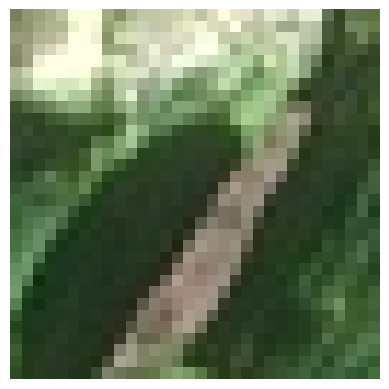

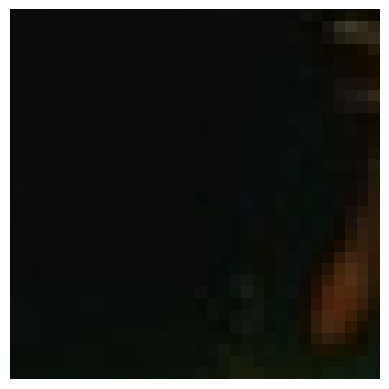

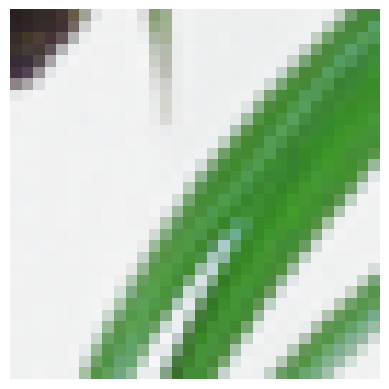

In [4]:
plt.imshow(train_dataset[0].permute(1, 2, 0))
plt.axis("off")
plt.show()

plt.imshow(val_dataset[0].permute(1, 2, 0))
plt.axis("off")
plt.show()

plt.imshow(test_dataset[0].permute(1, 2, 0))
plt.axis("off")
plt.show()

# Set up physics
Define a physics object corresponding to denoising problem with Gaussian noise and standard deviation $\sigma = 0.05$. See [this overview](https://deepinv.github.io/deepinv/auto_examples/physics/demo_physics_tour.html) and a [complete list](https://deepinv.github.io/deepinv/api/deepinv.physics.html) of physics models available at DeepInverse.

In [5]:
sigma = 25.0/255 # 0.05
physics = dinv.physics.Denoising(dinv.physics.GaussianNoise(sigma)) 

# Prepare dataloaders
Dataloaders handle loading datasets into memory. You can set up the batchs size and whether you want the elements be randomly reschuffled, see Remark 5.3.4.

In [6]:
n_channels = 3 
num_workers = 1 if torch.cuda.is_available() else 1

train_batch_size = 32 if torch.cuda.is_available() else 1
val_batch_size = 8 if torch.cuda.is_available() else 1
test_batch_size = 8 if torch.cuda.is_available() else 1

train_dataloader = DataLoader(
    train_dataset, batch_size=train_batch_size, num_workers=num_workers, shuffle=True
)

val_dataloader = DataLoader(
    val_dataset, batch_size=val_batch_size, num_workers=num_workers, shuffle=False
)

test_dataloader = DataLoader(
    test_dataset, batch_size=test_batch_size, num_workers=num_workers, shuffle=False
)

# Set up the Field-of-Experts



In [15]:
class ZeroMean(torch.nn.Module):
    def forward(self, X):
        return X - X.mean(dim=(-2,-1))[(...,) + (None,) *2]

class FoE(torch.nn.Module):
    r"""
    Fiel-of-Experts regularizer.

    :param int channels: Number of input channels.
    :param int num_filters: Number of filters channels (Tensor or int).
    :param int kernel_dim: dimension of the convolutional kernels.
    :param bool norm_weights: Whether to normalize weights.
    :param torch.device, str device: Device to put the model on.
    """

    def __init__(
        self,
        in_channels: int = 3,
        num_filters: int = 64,
        kernel_dim: int = 5,
        norm_weights: bool = False,
        act : str = "h",
        beta : float = 0.1,
        device: torch.device | str = "cpu",
        conv : bool = True,
        img_size : int = 9,
        alpha : float = 1.0,
    ):
        super(FoE, self).__init__()

        self.n_in_channels = in_channels
        self.n_filters = num_filters
        self.kernel_size = kernel_dim
        self.padding = (self.kernel_size - 1) // 2
            
        self.W = torch.nn.ModuleList(
            [torch.nn.Conv2d(self.n_in_channels, 4, self.kernel_size, bias=False, stride=1, padding=self.padding,padding_mode="zeros",device = device),
             torch.nn.Conv2d(4, 8, self.kernel_size, bias=False, stride=1, padding=self.padding,padding_mode="zeros",device = device),
             torch.nn.Conv2d(8, self.n_filters, self.kernel_size, bias=False, stride=1, padding=self.padding,padding_mode="zeros",device = device)
            ])

        for i in range(3):
            torch.nn.utils.parametrize.register_parametrization(self.W[i], "weight", ZeroMean())
        
        self.W_adj = torch.nn.ModuleList(
            [torch.nn.ConvTranspose2d(4,self.n_in_channels, self.kernel_size, bias=False, stride=1, padding=self.padding,padding_mode="zeros",device = device),
             torch.nn.ConvTranspose2d(8,4, self.kernel_size, bias=False, stride=1, padding=self.padding,padding_mode="zeros",device = device),
             torch.nn.ConvTranspose2d(self.n_filters,8, self.kernel_size, bias=False, stride=1, padding=self.padding,padding_mode="zeros",device = device)
            ])

        
        # self.dim = 2

        self.alphaj = torch.nn.Parameter(torch.randn(self.n_filters).abs().to(device))
        self.alphaj.requiresGrad = True
        self.alpha = alpha*torch.ones(1).to(device) 
        self.beta = beta
        self.betainv = beta**-1
        self.norm_weights = norm_weights
        self.device = device
        self.conv = conv
        self.img_size = img_size

        self.eig_vec = torch.randn([1,in_channels, img_size,img_size]).to(device)
        self.eig_val = torch.ones(1).to(device)


    def forward(self, x: torch.Tensor,**kwarg) -> torch.Tensor:
        r"""
        Calculate potential function of the FoE.

        :param torch.Tensor x: Input tensor of shape ``(B, C, H, W)``.
        """
        self.update_eigen()
        
        z = self.W[0](x)
        z = self.W[1](z)
        z = self.W[2](z)

        if self.norm_weights:
            z = z/self.eig_val

        z = z*self.alphaj.abs()[ (None,) *1 + (...,) + (None,) *2]
        if self.conv:
            idx = z.abs() < self.betainv
            z[idx] = 0.5*self.beta*z[idx].pow(2) 
            z[~idx] = z[~idx].abs() - 0.5*self.betainv
        else:
            z_one = z.clone()
            idx = z.abs() < self.betainv
            z[idx] = 0.5*self.beta*z[idx].pow(2) 
            z[~idx] = z[~idx].abs() - 0.5*self.betainv

            idx2 = z_one.abs() < 1.0
            z_one[idx2] = 0.5*z_one[idx2].pow(2) 
            z_one[~idx2] = z_one[~idx2].abs() - 0.5

            z = z.add(-z_one)

        z = z / self.alphaj.pow(2)[  (None,) *1 + (...,) + (None,) *2]
        
        return (self.alpha.abs() + 1e-6)*z.sum(dim=(1,2,3))

    @torch.enable_grad()
    def grad(self, x: torch.Tensor,**kwarg) -> torch.Tensor:
        r"""
        Calculate the gradient of the potential function.

        :param torch.Tensor x: Input tensor of shape ``(B, C, H, W)``.
        """
        x = x.requires_grad_(True)
        out = self.forward(x)
        return torch.autograd.grad(
            outputs=out,
            inputs=x,
            grad_outputs=torch.ones_like(out),
            create_graph=True,
            retain_graph=True,
            only_inputs=True,
        )[0]

    def update_eigen(self):
        z = self.eig_vec

        for i in range(3):
            z = self.W[i](z)
        
        for i in torch.arange(2,-1,-1):
            with torch.no_grad():
                _ = self.W_adj[i].weight.copy_ (self.W[i].weight)
                z = self.W_adj[i](z)
    
        self.eig_val = z.norm().sqrt().detach()
        self.eig_vec = (z/z.norm()).detach()

In [8]:
class LearnedPrior(dinv.optim.Prior):
    def __init__(self,regularizer):
        super().__init__()
        self.explicit_prior = True
        self.reg = regularizer

    def fn(self, x, *args, **kwargs):
        return self.reg(x)

    def grad(self, x, *args, **kwargs):
        return self.reg.grad(x)

In [9]:
class Solver(torch.nn.Module):
    def __init__(self,T, K,regularizer, init = 'y'):
        super().__init__()
        self.T=T
        self.K=K
        self.reg = regularizer
        self.device = regularizer.device
        self.init = init

        params_algo = {
                "stepsize": 1.0/(((self.reg.alpha.abs().detach() + 1e-6))*self.reg.beta + 1),
                "lambda": 1.0,
                "beta": 1.0,
                }

        data_fidelity = dinv.optim.data_fidelity.L2()
        
        self.solver = dinv.optim.optim_builder(
                iteration="GD",
                prior=LearnedPrior(self.reg),
                data_fidelity=data_fidelity,
                early_stop=False,
                max_iter=1,
                verbose=False,
                params_algo=params_algo,
                device = self.device,
            )
        self.solver.eval()

        self.solver_unf = dinv.optim.optim_builder(
                iteration="GD",
                prior=LearnedPrior(self.reg), 
                data_fidelity=data_fidelity,
                early_stop=False,
                max_iter=K,
                verbose=False,
                params_algo=params_algo,
                unfold=True,
                trainable_params=self.reg.parameters(),
                device = self.device,
            )
        self.solver_unf.train()
        
    def forward(self,
        y: torch.Tensor,
        physics: dinv.physics.Physics,
        train: bool = False,
        **kwargs,
    ) -> torch.Tensor:

        if self.reg.conv:
            beta = self.reg.beta
        else:
            beta = max(self.reg.beta,1)
            
        if self.reg.norm_weights:
            stepsize = 1.0/((self.reg.alpha.abs().detach() + 1e-6)*beta + 1)
        else:
            stepsize = 1.0/((self.reg.alpha.abs().detach() + 1e-6)*self.reg.eig_val*beta + 1)

        self.solver.init_params_algo["stepsize"] = stepsize

        if isinstance(self.T, tuple):
            T = torch.randint(low=self.T[0],high=self.T[1],size=[1]).item()
        else:
            T = self.T
            
        self.solver.max_iter = T - self.K
        self.solver.fixed_point.max_iter = T - self.K

        if self.init == 'random':
            init = torch.randn(size=y.shape).to(self.device)
        elif self.init == 'pinv':
            init = physics.A_dagger(y)
        else:
            init = y
        
        x_hat = self.solver(y, physics, init=init).detach()
        x_hat = x_hat.clone(memory_format=torch.contiguous_format).detach()
        x_hat = x_hat.requires_grad_(True)
        y = y.requires_grad_(True)
        
        if self.reg.norm_weights:
            stepsize = 1.0/((self.reg.alpha.abs() + 1e-6)*beta + 1)
        else:
            stepsize = 1.0/((self.reg.alpha.abs() + 1e-6)*self.reg.eig_val*beta + 1)
        
        self.solver_unf.init_params_algo["stepsize"] = stepsize
        x_hat2 = self.solver_unf(y, physics, init=x_hat)

        return x_hat2

In [35]:
reg = FoE(
    in_channels=3, num_filters=16, kernel_dim = 5, device = device, conv = True, beta = 1e-1, img_size = img_size, norm_weights = True, alpha = 1e3
)
print(reg.parameters)

solver = Solver(200,10,reg, init='pinv')
print(solver.reg.alphaj)
print(solver.reg.alpha)

<bound method Module.parameters of FoE(
  (W): ModuleList(
    (0): ParametrizedConv2d(
      3, 4, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False
      (parametrizations): ModuleDict(
        (weight): ParametrizationList(
          (0): ZeroMean()
        )
      )
    )
    (1): ParametrizedConv2d(
      4, 8, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False
      (parametrizations): ModuleDict(
        (weight): ParametrizationList(
          (0): ZeroMean()
        )
      )
    )
    (2): ParametrizedConv2d(
      8, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False
      (parametrizations): ModuleDict(
        (weight): ParametrizationList(
          (0): ZeroMean()
        )
      )
    )
  )
  (W_adj): ModuleList(
    (0): ConvTranspose2d(4, 3, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
    (1): ConvTranspose2d(8, 4, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
    (2): ConvTranspose2d(16, 8, ker

# Set up a Trainer
Trainer is a ready-made class for training a network. It takes model, physics, dataloaders, and training parameters as input and trains the network accordingly. Try different numbers of epochs and learning rates to see which works best. Note: Given the limited free GPU access on Colab, going beyond 300 epochs is not recommended. 

See https://deepinv.github.io/deepinv/user_guide/training/trainer.html#trainer
and https://deepinv.github.io/deepinv/api/stubs/deepinv.Trainer.html for more details.

In [42]:
verbose = True  # print training information
wandb_vis = False  # plot curves and images in Weight&Bias

epochs = 100 # choose training epochs
learning_rate = 1e-2

# choose training losses
losses = [dinv.loss.SupLoss(metric=dinv.metric.MSE())]#, ZeroSumLoss()]

# choose optimizer and scheduler
optimizer = torch.optim.Adam(solver.reg.parameters(), lr=learning_rate, weight_decay=1e-8)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer,step_size=epochs,gamma=0.99) 


trainer = dinv.Trainer(
    solver,
    device=device,
    save_path=str(CKPT_DIR / operation),
    verbose=verbose,
    wandb_vis=wandb_vis,
    physics=physics,
    epochs=epochs,
    scheduler=scheduler,
    losses=losses,
    optimizer=optimizer,
    show_progress_bar=False,  # disable progress bar for better vis in sphinx gallery.
    train_dataloader=train_dataloader,
    eval_dataloader=val_dataloader,
    plot_images=False, # You can plot images, to see the network's actual denoising. Significantly increases the size of the notebook.
    plot_measurements=True,
    online_measurements=True,  # Do our datasets contain both (x_i, y_i) or we want to generate y_i = physics(x_i) on the fly?
    no_learning_method = "y", # Baseline to compare with: options 'y', 'A_dagger', 'A_adjoint', 'prox_l2'
    ckp_interval = 20, # Store network parameters every ckp_interval epochs. Very useful in practice.
)

In [37]:
trainer.train()
print(solver.reg.alphaj)
print(solver.reg.alpha)

The model has 8617 trainable parameters


/homes/numerik/melnyk/scratch/anaconda3_new/lib/python3.13/site-packages/deepinv/training/trainer.py:1352: UserWarning: non_blocking_transfers=True but DataLoader.pin_memory=False; set pin_memory=True to overlap host-device copies with compute.
  self.setup_train()


Train epoch 0: TotalLoss=0.008, PSNR=21.73
Eval epoch 0: PSNR=23.251
Best model saved at epoch 1
Train epoch 1: TotalLoss=0.005, PSNR=23.928
Eval epoch 1: PSNR=24.638
Best model saved at epoch 2
Train epoch 2: TotalLoss=0.003, PSNR=25.448
Eval epoch 2: PSNR=25.21
Best model saved at epoch 3
Train epoch 3: TotalLoss=0.003, PSNR=25.882
Eval epoch 3: PSNR=25.18
Train epoch 4: TotalLoss=0.003, PSNR=25.5
Eval epoch 4: PSNR=25.3
Best model saved at epoch 5
Train epoch 5: TotalLoss=0.003, PSNR=25.67
Eval epoch 5: PSNR=25.426
Best model saved at epoch 6
Train epoch 6: TotalLoss=0.003, PSNR=25.757
Eval epoch 6: PSNR=25.566
Best model saved at epoch 7
Train epoch 7: TotalLoss=0.003, PSNR=25.8
Eval epoch 7: PSNR=25.617
Best model saved at epoch 8
Train epoch 8: TotalLoss=0.003, PSNR=25.925
Eval epoch 8: PSNR=26.025
Best model saved at epoch 9
Train epoch 9: TotalLoss=0.003, PSNR=25.984
Eval epoch 9: PSNR=26.2
Best model saved at epoch 10
Train epoch 10: TotalLoss=0.002, PSNR=26.367
Eval epoch 10:

Model, optimizer, scheduler, epoch_start successfully loaded from checkpoint: ckpts/denoising/26-01-23-11:39:58/ckp_best.pth.tar
Eval epoch 0: PSNR=26.549, PSNR no learning=20.153


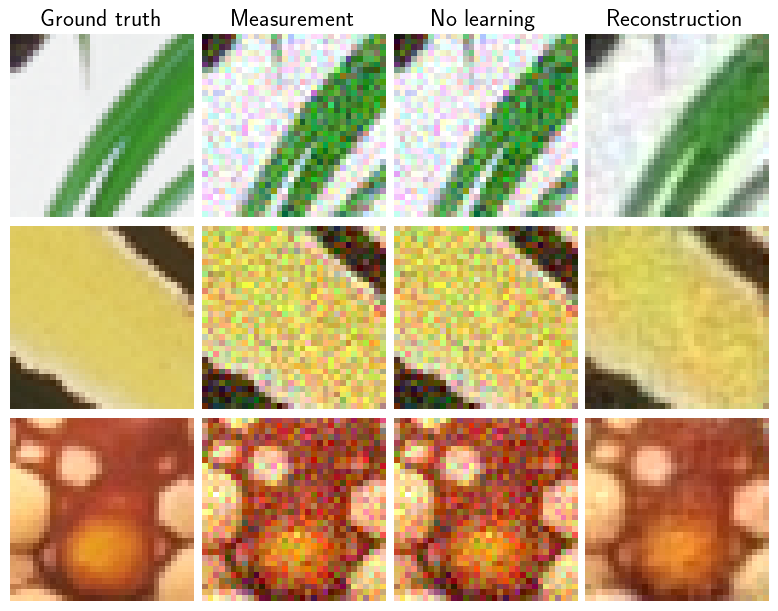

Test results:
PSNR no learning: 20.153 +- 0.111
PSNR: 26.549 +- 1.055


{'PSNR no learning': 20.15295664469401,
 'PSNR no learning_std': 0.11058232698663245,
 'PSNR': 26.548688252766926,
 'PSNR_std': 1.0551586324752777}

In [43]:
# load model with best validation PSNR
model = trainer.load_best_model()
trainer.plot_images = True
trainer.test(test_dataloader)

# Plot an example of reconstruction

In [44]:
from deepinv.utils.plotting import plot_inset, plot

def show_image_comparison(images, suptitle=None, ref=None):
    """Display various images restoration with PSNR and zoom-in"""

    titles = list(images.keys())
    if "Original" in images or ref is not None:
        # If the original image is in the dict, add PSNR in the titles.
        image = images["Original"] if "Original" in images else ref
        psnr = [dinv.metric.cal_psnr(image, im).item() for im in images.values()]
        titles = [
            f"{name} \n (PSNR: {psnr:.2f})" if name != "Original" else name
            for name, psnr in zip(images.keys(), psnr)
        ]
    # Plot the images with zoom-in
    fig = plot_inset(
        list(images.values()),
        titles=titles,
        extract_size=0.2,
        extract_loc=(0.5, 0.0),
        inset_size=0.5,
        return_fig=True,
        show=False,
        figsize=(len(images) * 1.5, 2.5),
    )

    # Add a suptitle if it is provided
    if suptitle:
        plt.suptitle(suptitle, size=12)
        plt.tight_layout()
        fig.subplots_adjust(top=0.85, bottom=0.02, left=0.02, right=0.95)
        plt.show()

/tmp/ipykernel_10375/3393706312.py:30: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


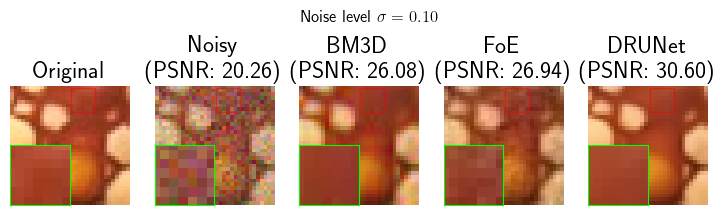

In [46]:
bm3d = dinv.models.BM3D()
drunet = dinv.models.DRUNet().to(device)

x = test_dataset[2].to(device)
x = x[None,...]
y = physics(x)


denoiser_results = {
    "Original": x,
    "Noisy": y,
    "BM3D": bm3d(y, sigma),
    "FoE": solver(y,physics),
    "DRUNet": drunet(y, sigma),
}
show_image_comparison(denoiser_results, suptitle=rf"Noise level $\sigma={sigma:.2f}$")